<a href="https://colab.research.google.com/github/delaneydow/ncl_diffusion/blob/main/02_train_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Train the diffusion model (MONAI, label-conditional)

Pixel-space DDPM with MONAI's `DiffusionModelUNet`, conditioned on the 6 RSNA labels through cross-attention, with
classifier-free guidance. Runs on the cache from notebook 01, **train split only** (val split is used for the loss curve).
Training resumes automatically from `ckpt_last.pt`, so if Colab disconnects, reconnect and re-run the cells.

**Budget check:** the default 40 epochs on 6000 images is only about 5k optimizer steps, which is a "does it work at
all" run. For samples worth evaluating, plan on tens of thousands of steps (raise `EPOCHS` once the smoke run looks sane).

In [ ]:
# ====== BOOTSTRAP (identical in every notebook) ======
# Mounts Drive, links the project folder, installs anything missing, puts the package on sys.path.
import os, sys, importlib.util, importlib.metadata, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules

PROJECT = "/content/drive/MyDrive/ncl_diffusion" if IN_COLAB else os.path.abspath("ct_diffusion_project")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(PROJECT, exist_ok=True)
LINK = "/content/ncl_diffusion_project" if IN_COLAB else PROJECT   # short path used everywhere below
if LINK != PROJECT and not os.path.exists(LINK):
    os.symlink(PROJECT, LINK)

# pip name -> import name.
# NOTE: no `monai-generative` any more. MONAI >= 1.4 ships the diffusion code in core.
_pip = {"einops": "einops", "pydicom": "pydicom", "kaggle": "kaggle", "scikit-learn": "sklearn", "tqdm": "tqdm",
        "opencv-python-headless": "cv2", "pandas": "pandas", "matplotlib": "matplotlib",
        "torchmetrics": "torchmetrics", "torch-fidelity": "torch_fidelity"}
_missing = [p for p, m in _pip.items() if importlib.util.find_spec(m) is None]
try:
    from packaging.version import Version
    _monai_ok = Version(importlib.metadata.version("monai")) >= Version("1.4")
except Exception:          # not installed, or version string we can't parse
    _monai_ok = False
if not _monai_ok:
    _missing.append("monai>=1.4")
if _missing:
    print("installing:", _missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
if LINK not in sys.path:
    sys.path.insert(0, LINK)
print("project:", PROJECT)

Mounted at /content/drive
installing: ['pydicom', 'torchmetrics', 'torch-fidelity', 'monai>=1.4']
project: /content/drive/MyDrive/ncl_diffusion


In [ ]:
import time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import Image, display
from ncl_diffusion.config import Config
from ncl_diffusion import data, models, train, synth         # imports register datasets / backbones / label plans
from ncl_diffusion.data import load_cache, make_dataset, make_loader
from ncl_diffusion.models import DiffusionSystem
from ncl_diffusion.train import train_diffusion, load_system
from ncl_diffusion.registry import LABEL_PLANS
from ncl_diffusion.utils import get_device, count_params, seed_everything, show_grid, to_model_range, to_unit_range

device = get_device()
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(switch the runtime to GPU!)")

device: cuda NVIDIA RTX PRO 6000 Blackwell Server Edition


## Settings
Anything in `cfg` can be changed with a dotted override, so an ablation is one line. A few you may want later are
commented out.


In [ ]:
import json
VARIANT      = "full_head"     # "full_head" or "skull_stripped"
HEALTHY_ONLY = False           # see the tradeoff above
TARGET_STEPS = 30_000          # adjust after you see s/step from the timing cell

cfg = Config.load(Path(LINK) / "config.json")
cfg.paths.project = LINK
SMOKE = False
cfg = cfg.override({
    "train.run_name": f"ddpm_{'smoke' if SMOKE else 'base'}_{VARIANT}{'_healthy' if HEALTHY_ONLY else ''}",
    "train.epochs": 2 if SMOKE else 100,                 # replaced below once we know steps per epoch
    "train.sample_every": 1 if SMOKE else 5,
    # "diffusion.conditional": False,                    # use with HEALTHY_ONLY = True (all labels are zero)
    # --- ablations to try later ---
    # "diffusion.num_channels": [64, 128, 256, 256], "diffusion.attention_levels": [False, False, True, True],
    #     "diffusion.num_head_channels": [0, 0, 64, 64],          # deeper / wider U-Net
    # "diffusion.prediction_type": "v_prediction",
    # "diffusion.cond_drop": 0.2,                                  # more unconditional training -> stronger guidance
    # "diffusion.conditional": False,                              # unconditional baseline
})

seed_everything(cfg.data.seed)
run_dir = cfg.run_dir(); run_dir.mkdir(parents=True, exist_ok=True)
cfg.save(run_dir / "config.json")          # exact settings of this run, stored next to its checkpoints
print("run dir:", run_dir)
print("batch size:", cfg.data.batch_size, "| channels:", cfg.diffusion.num_channels, "| attention:", cfg.diffusion.attention_levels)

run dir: /content/ncl_diffusion_project/runs/ddpm_base_full_head
batch size: 32 | channels: [64, 128, 256] | attention: [False, False, True]


In [ ]:
variants = json.loads((Path(LINK) / "cache_variants.json").read_text())
images, man = load_cache(Path(variants[VARIANT]))

# strip_ok flags always come from the skull-stripped manifest, so BOTH variants train on identical rows
flags = pd.read_csv(Path(variants["skull_stripped"]) / "manifest.csv").set_index("sample_id").strip_ok
man["strip_ok"] = man.sample_id.map(flags)
keep = man.strip_ok.fillna(False).astype(bool)
if HEALTHY_ONLY:
    keep &= man["any"] == 0
man = man[keep]
print(f"{VARIANT}: {len(man)} rows kept | per split:\n{man.split.value_counts().to_string()}")
print("hemorrhage fraction:", man["any"].mean().round(3))
man.to_csv(run_dir / "rows_used.csv", index=False)       # records exactly which slices this run saw

lc, in_ch = cfg.data.label_cols, images.shape[1]
train_ds, val_ds = make_dataset(images, man, "train", lc), make_dataset(images, man, "val", lc)
train_loader = make_loader(train_ds, cfg.data.batch_size, True, cfg.data.num_workers, drop_last=True)
val_loader = make_loader(val_ds, cfg.data.batch_size, False, cfg.data.num_workers)

import math
EPOCHS = 2 if SMOKE else math.ceil(TARGET_STEPS / len(train_loader))
cfg = cfg.override({"train.epochs": EPOCHS})
cfg.save(run_dir / "config.json")
print(f"train {len(train_ds)} | val {len(val_ds)} | {EPOCHS} epochs = {EPOCHS * len(train_loader):,} steps")

# row-alignment check: should print ~0 (see note below)
r = man[man.split == "train"].iloc[0]
print("alignment check:", float(np.abs(train_ds[0]["image"].numpy().ravel() * 255 - images[r.idx].ravel()).max()))

# ---- model
system = DiffusionSystem(cfg, in_ch, len(lc))
print(f"denoiser+conditioner parameters: {count_params(system) / 1e6:.1f} M")

# gpu overhead check
print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB of {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

full_head: 8007 rows kept | per split:
split
train    5548
test     1652
val       807
hemorrhage fraction: 0.198
train 5548 | val 807 | 174 epochs = 30,102 steps
alignment check: 0.0
denoiser+conditioner parameters: 23.0 M
peak GPU memory: 18.9 GB of 102.0 GB


In [ ]:
# ---- sanity: one batch through the loss, and a rough speed estimate (no weights are updated)
system.to(device).train()
it = iter(train_loader)
def _batch():
    b = {k: v.to(device) for k, v in next(it).items() if torch.is_tensor(v)}
    b["image"] = to_model_range(b["image"]); return b

use_amp = cfg.train.amp and device == "cuda"
t0 = None
for i in range(11):
    if i == 1:                                   # skip the first step (CUDA warm-up)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()
    with torch.autocast(device, dtype=torch.float16, enabled=use_amp):
        loss, logs = system.training_step(_batch())
    loss.backward(); system.zero_grad(set_to_none=True)
if device == "cuda": torch.cuda.synchronize()
per_step = (time.time() - t0) / 10
print(f"loss at init {logs['diffusion']:.3f} (about 1.0 is expected)  |  {per_step:.2f} s/step  |  "
      f"about {per_step * len(train_loader) / 60:.1f} min/epoch")

loss at init 0.999 (about 1.0 is expected)  |  0.15 s/step  |  about 0.4 min/epoch


In [ ]:
# ---- preview labels: a fixed set that covers each hemorrhage subtype + negatives (same set every epoch)
preview = LABEL_PLANS.build("balance", man[man.split == "train"], lc, 24, cfg.data.seed)
print("preview label matrix:", preview.shape, "| columns:", lc)

preview label matrix: (24, 6) | columns: ['epidural', 'intraparenchymal', 'intraventricular', 'subarachnoid', 'subdural', 'any']


## Train
Loss curve: `train_diffusion` (noise-prediction MSE) vs `val_diffusion` (fixed noise/timesteps, so it is comparable
across epochs). Sample grids from the EMA weights are saved to `run_dir/samples/` every few epochs.

In [ ]:
hist = train_diffusion(system, train_loader, val_loader, cfg, run_dir, device, preview_labels=preview)

epoch 1/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 1, 'train_diffusion': 0.20556, 'train_total': 0.20556, 'val_diffusion': 0.01849}


epoch 2/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 2, 'train_diffusion': 0.01621, 'train_total': 0.01621, 'val_diffusion': 0.01488}


epoch 3/174:   0%|          | 0/173 [00:00<?, ?it/s]

...

{'epoch': 172, 'train_diffusion': 0.00936, 'train_total': 0.00936, 'val_diffusion': 0.00952}


epoch 173/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 173, 'train_diffusion': 0.00884, 'train_total': 0.00884, 'val_diffusion': 0.00941}


epoch 174/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 174, 'train_diffusion': 0.0094, 'train_total': 0.0094, 'val_diffusion': 0.00945}


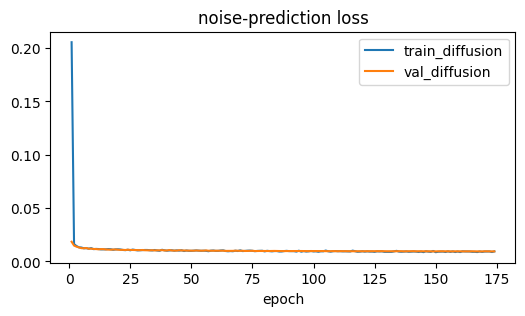

latest preview: /content/ncl_diffusion_project/runs/ddpm_base_full_head/samples/ep174.png


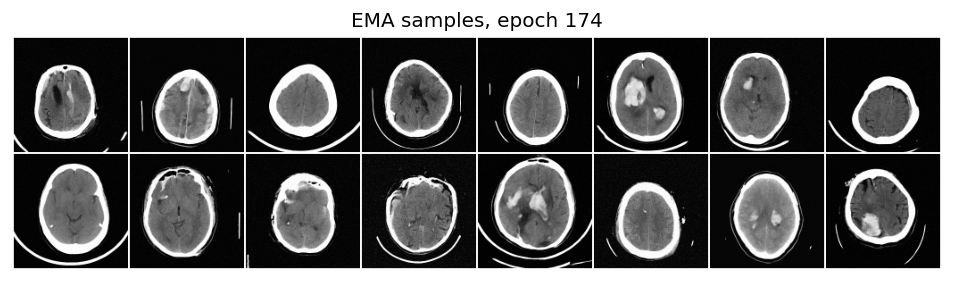

In [ ]:
h = pd.read_csv(run_dir / "history.csv")
h.plot(x="epoch", y=["train_diffusion", "val_diffusion"], figsize=(6, 3), title="noise-prediction loss"); plt.show()

from glob import glob
latest = sorted(glob(str(run_dir / "samples" / "*.png")))
if latest:
    print("latest preview:", latest[-1]); display(Image(latest[-1]))

## Qualitative check: guidance strength
Same labels and same noise seed at three guidance scales. Scale 1 = no guidance (weakest label control);
higher = stronger label adherence but less diversity and eventually over-saturated images.
For the augmentation experiments the scale becomes a knob we sweep (`cfg.sample.cfg_scale`).

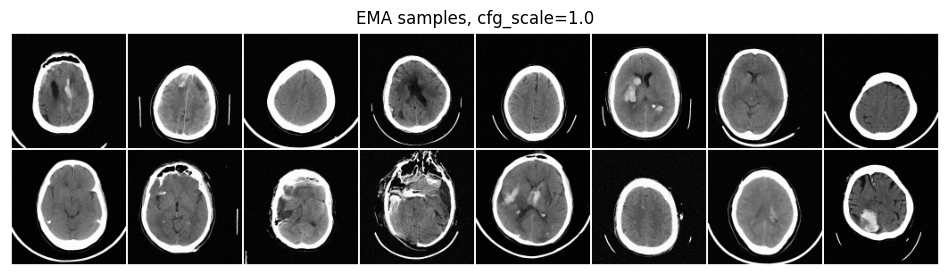

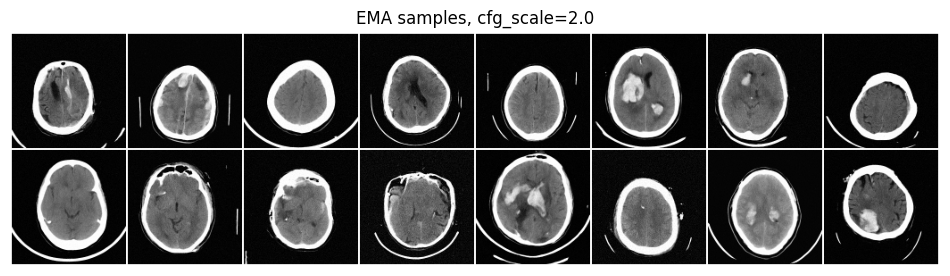

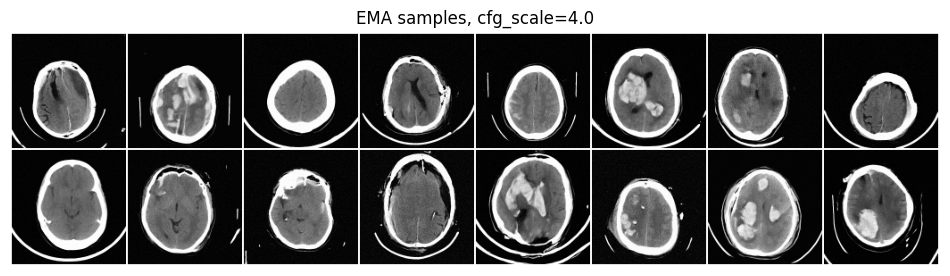

In [ ]:
ema_sys = load_system(cfg, run_dir, in_ch, len(lc), device, which="best")      # EMA weights of the best-val-loss epoch
lab = torch.tensor(preview[:16]).float()
for s in (1.0, 2.0, 4.0):
    x = ema_sys.sample(lab, steps=cfg.sample.steps, cfg_scale=s, generator=torch.Generator(device).manual_seed(0))
    show_grid(to_unit_range(x).cpu(), nrow=8, title=f"EMA samples, cfg_scale={s}", figsize=(12, 3.2))

## Adding a custom denoiser (if needed)
Everything is picked by name in the config, so a custom architecture only has to follow one contract:
`builder(d, in_channels, cross_attention_dim) -> nn.Module` with `forward(x, timesteps, context=None)` returning a
tensor shaped like `x`. To keep it permanently, put the function in `models/backbones.py`; registering it here only
lasts for this session.

In [ ]:
# from ncl_diffusion.registry import BACKBONES
# @BACKBONES.register("my_unet")
# def my_unet(d, in_channels, cross_attention_dim=None):
#     return MyUNet(in_channels=in_channels, context_dim=cross_attention_dim)   # your nn.Module
# cfg = cfg.override({"diffusion.backbone": "my_unet", "train.run_name": "ddpm_myunet"})
# ...then re-run from the "data" cell down.

**Next:** `03_train_gan.ipynb` trains the GAN baseline on the same train split with the same labels, so the two
generators are directly comparable. After that, generation + evaluation (FID variants, memorization, downstream
classifier with real + synthetic) builds on `synth.py`, `metrics.py` and `experiments.py`.